# Árbol de decisión: primer modelo de clasificación
**Minería de Datos I — ISTEA (Clase 9)** · Prof. Kevin Kovacs

**Objetivo:** entrenar un árbol de decisión y aprender a interpretarlo.
**Datos:** dataset Iris (150 flores de 3 especies), incluido en scikit-learn.
**Qué hice:** separé los datos en entrenamiento y test (80/20), entrené un árbol con profundidad máxima 4, lo evalué con accuracy y `classification_report` y grafiqué el árbol.
**Resultado principal:** 100% de accuracy en las 30 flores de test.
**Qué aprendí:** a leer un árbol (nodo raíz, gini, samples, value) y que un 100% en un dataset de práctica no dice cómo funcionaría el modelo con datos reales.

*Notebook desarrollado durante la cursada de Minería de Datos I (ISTEA).*

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

In [2]:
iris = load_iris()
print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [3]:
X = iris.data
y = iris.target

In [4]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [5]:
# split en train y test

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
len(X_train)

120

In [8]:
len(X_test)

30

In [9]:
model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42) # hiperparametros

In [10]:
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

**evaluando las prediciones**

In [11]:
predicion_arbol = model.predict(X_test)

In [12]:
## lo evaluamos con accuracy
from sklearn.metrics import accuracy_score
predi1 = accuracy_score(y_test, predicion_arbol)
predi1

1.0

In [13]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predicion_arbol))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



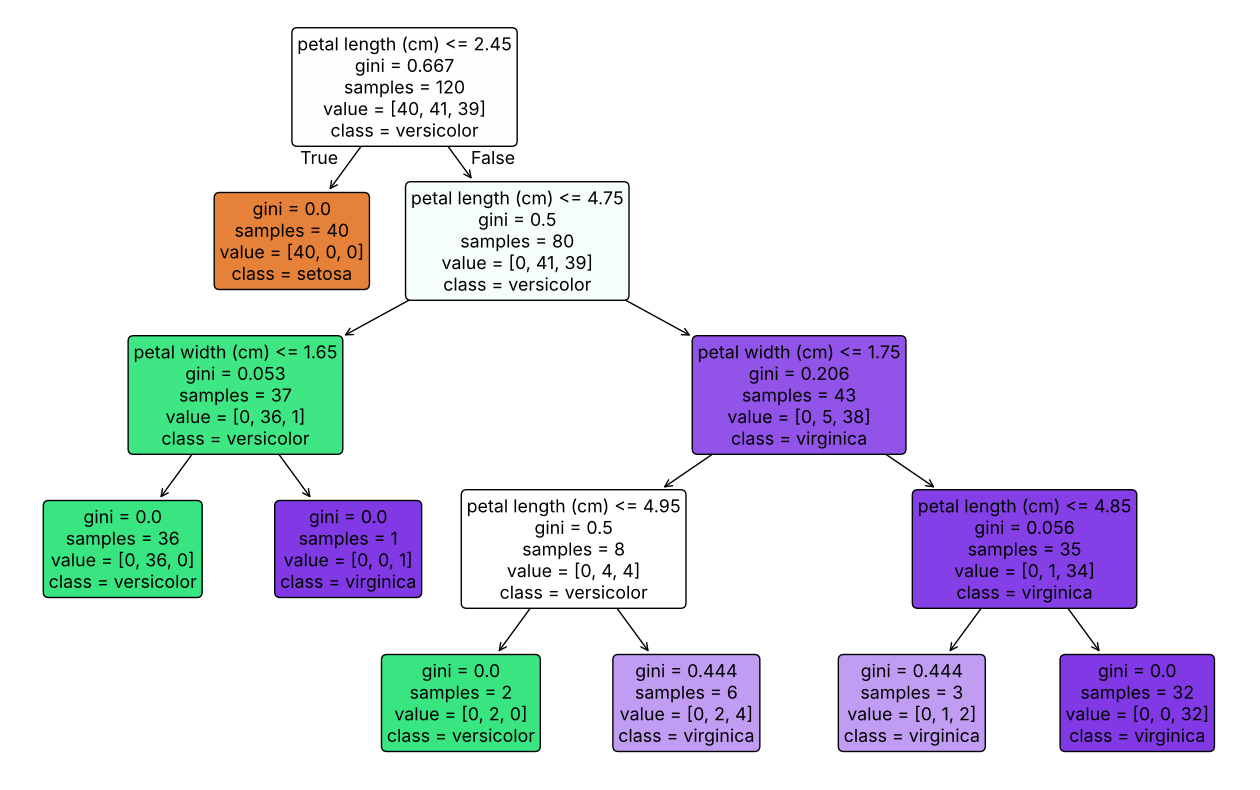

In [14]:
# 4. Graficar el árbol
plt.figure(figsize=(16, 10))
plot_tree(
    model,
    filled=True,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    rounded=True
)
plt.show()

## ¿Cómo interpretar este árbol de decisión?

Este gráfico representa un **árbol de decisión** utilizado para clasificar flores del dataset *Iris* en tres clases: **setosa, versicolor y virginica**.

Un árbol de decisión funciona tomando una característica de una observación y realizando preguntas sucesivas. Según la respuesta a cada pregunta, la observación sigue una determinada **rama** hasta llegar a una **hoja**, donde finalmente se realiza la predicción.

### 1. El nodo raíz

El nodo ubicado arriba de todo es el **nodo raíz**:

> `petal length (cm) <= 2.45`

Esto significa que el árbol comienza preguntando si la longitud del pétalo es menor o igual a 2.45 cm.

* Si la respuesta es **True**, se sigue la rama izquierda.
* Si la respuesta es **False**, se sigue la rama derecha.

En este caso, todas las 40 observaciones que tienen una longitud de pétalo menor o igual a 2.45 cm pertenecen a la clase **setosa**. Por eso, esa rama termina directamente en una hoja.

### 2. Las ramas

Cada línea que conecta dos nodos representa una **rama** y corresponde al resultado de la condición del nodo anterior.

Por ejemplo:

`petal length <= 2.45`

genera dos caminos:

* **True:** la longitud del pétalo es menor o igual a 2.45.
* **False:** la longitud del pétalo es mayor a 2.45.

De esta manera, cada observación va recorriendo el árbol según sus características hasta llegar a una predicción.

### 3. Los nodos

Cada recuadro que no es una hoja contiene una nueva condición que permite seguir dividiendo los datos.

Por ejemplo, después de descartar el caso `petal length <= 2.45`, el árbol pregunta:

`petal length <= 4.75`

y posteriormente utiliza variables como:

* `petal width`
* `petal length`

El árbol va seleccionando las características y los puntos de corte que permiten separar mejor las distintas clases.

### 4. ¿Qué significa `gini`?

`gini` representa la **impureza de Gini** del nodo.

Es una medida de qué tan mezcladas están las clases dentro de ese nodo:

* **Gini = 0:** todas las observaciones pertenecen a una única clase. El nodo es completamente puro.
* **Gini alto:** hay una mayor mezcla entre las distintas clases.

Por ejemplo, la hoja:

> `gini = 0.0`
> `samples = 40`
> `value = [40, 0, 0]`
> `class = setosa`

es completamente pura: las 40 observaciones son setosa.

En cambio, el nodo raíz tiene:

> `gini = 0.667`
> `value = [40, 41, 39]`

porque contiene observaciones de las tres clases y, por lo tanto, está mucho más mezclado.

### 5. ¿Qué significa `samples`?

`samples` indica **cuántas observaciones del dataset llegaron a ese nodo**.

Por ejemplo:

> `samples = 80`

significa que 80 observaciones llegaron a ese punto del árbol.

A medida que descendemos por el árbol, las observaciones se van repartiendo entre las diferentes ramas, por lo que normalmente la cantidad de `samples` disminuye.

### 6. ¿Qué significa `value`?

`value` muestra cuántas observaciones de cada clase hay dentro del nodo.

En este árbol el orden es:

`[setosa, versicolor, virginica]`

Por ejemplo:

> `value = [0, 36, 1]`

significa que en ese nodo hay:

* 0 observaciones de setosa
* 36 de versicolor
* 1 de virginica

Por eso la clase predicha es **versicolor**, ya que es la clase mayoritaria.

### 7. ¿Qué significa `class`?

`class` indica la **clase que el árbol predice en ese nodo**.

En los nodos internos, corresponde a la clase mayoritaria entre las observaciones que llegaron allí.

En las hojas, representa directamente la predicción final del árbol.

### 8. ¿Qué es una hoja?

Una **hoja** es un nodo final: ya no se realizan más divisiones.

Cuando una nueva observación llega a una hoja, el árbol utiliza la clase indicada en `class` como su predicción.

Por ejemplo:

> `gini = 0.0`
> `samples = 32`
> `value = [0, 0, 32]`
> `class = virginica`

significa que 32 observaciones llegaron a esa hoja y todas son virginica. Por lo tanto, una observación que siga ese camino será clasificada como **virginica**.

No todas las hojas tienen que ser perfectamente puras. Por ejemplo:

> `value = [0, 2, 4]`
> `class = virginica`

contiene 2 observaciones de versicolor y 4 de virginica. En ese caso, la predicción es virginica porque es la clase mayoritaria, aunque todavía existe cierta mezcla.

### 9. ¿Qué podemos deducir del árbol?

Una de las cosas más interesantes que podemos observar es que **la longitud y el ancho del pétalo son variables muy importantes para separar las especies**.

En particular, la primera división utiliza `petal length <= 2.45`. Esta división separa perfectamente las 40 observaciones de setosa del resto.

También podemos observar que el árbol necesita más divisiones para distinguir entre **versicolor y virginica**, ya que estas dos clases presentan características más similares entre sí.

Por lo tanto, el árbol no solo permite realizar predicciones, sino que también nos permite **interpretar qué variables y qué puntos de corte son útiles para la clasificación**.

### Resumen

Para leer un árbol de decisión podemos seguir siempre este orden:

1. **Nodo:** ¿qué condición se está evaluando?
2. **Rama:** ¿la condición es True o False?
3. **Samples:** ¿cuántas observaciones llegaron hasta acá?
4. **Value:** ¿cómo se distribuyen esas observaciones entre las clases?
5. **Gini:** ¿qué tan mezcladas están las clases?
6. **Class:** ¿cuál es la clase que se predice?
7. **Hoja:** ¿cuál es la predicción final?

En definitiva, podemos interpretar el árbol como una secuencia de preguntas que van dividiendo progresivamente los datos hasta llegar a una decisión final.


## Conclusiones
- El árbol empieza preguntando por la longitud del pétalo (≤ 2,45 cm). Con esa sola pregunta separa todas las flores *setosa*.
- Clasifica bien las 30 flores de test (accuracy 1,0). Iris es un dataset muy limpio y con especies bien diferenciadas, por eso resulta tan fácil.
- `max_depth = 4` limita la cantidad de preguntas que puede hacer el árbol. Sirve para que no memorice los datos de entrenamiento (sobreajuste).
- Con datos reales el resultado es muy distinto: en el notebook 05 el mismo tipo de modelo se aplica a datos de RRHH.